# Notebook 09 _ Étude de transférabilité au contexte marocain

## Objectif

L'objectif de ce notebook est d'étudier la **transférabilité de la méthodologie**
de prévision H+1 vers un contexte énergétique différent : le Maroc.

Le jeu de données utilisé contient des profils horaires nationaux pour l'année
2015, incluant :

- la demande électrique ;
- le facteur de capacité solaire ;
- le facteur de capacité éolien terrestre.

Contrairement au cas allemand étudié dans le Notebook 08, ces séries ne
constituent pas toutes des mesures opérationnelles réelles du système électrique.

Les profils solaire et éolien sont modélisés sous forme de facteurs de capacité,
et la demande provient d'un profil modélisé à l'échelle nationale.

Cette expérimentation ne doit donc pas être interprétée comme une validation
opérationnelle du réseau marocain.

Elle vise à déterminer si la **démarche méthodologique** développée dans le PFE
reste applicable dans un autre contexte géographique et énergétique.

Le protocole retenu repose sur :

1. contrôle de qualité et de continuité temporelle ;
2. construction des cibles à H+1 ;
3. création de variables temporelles sans fuite de données ;
4. découpage chronologique entraînement / validation / test ;
5. comparaison d'une régression linéaire et de HistGradientBoosting ;
6. comparaison à une baseline naïve de persistance ;
7. évaluation avec MAE, RMSE et R².

In [1]:
# IMPORTATION

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

from sklearn.preprocessing import StandardScaler


# CHEMINS DU PROJET

NOTEBOOK_DIR = Path.cwd()

if NOTEBOOK_DIR.name == "notebooks":
    PROJECT_DIR = NOTEBOOK_DIR.parent
else:
    PROJECT_DIR = NOTEBOOK_DIR

RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
RESULTS_DIR = PROJECT_DIR / "results"
FIGURES_DIR = PROJECT_DIR / "figures"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

MOROCCO_FILE = (
    RAW_DIR / "morocco_data.csv"
)

print("Projet :", PROJECT_DIR)
print("Dataset Maroc :", MOROCCO_FILE)

print("\nExistence du fichier :")
print(MOROCCO_FILE.exists())

Projet : c:\Users\celes\Desktop\PFE
Dataset Maroc : c:\Users\celes\Desktop\PFE\data\raw\morocco_data.csv

Existence du fichier :
True


## 1. Variables utilisées

Ce fichier marocain contient plusieurs profils énergétiques horaires.

Pour cette étude, trois séries sont retenues afin de rester cohérent avec
le problème principal du PFE :

- `demand_GW` : profil national de demande électrique ;
- `solar_CF` : facteur de capacité solaire ;
- `wind_onshore_CF` : facteur de capacité éolien terrestre.

Le facteur de capacité représente une production normalisée par rapport à
la capacité installée. Il est donc sans unité et généralement compris entre
0 et 1.

Les valeurs numériques de RMSE obtenues pour ces facteurs de capacité ne
doivent pas être comparées directement aux RMSE exprimés en MW ou GW sur
d'autres datasets.

In [2]:
# CHARGEMENT DU DATASET MAROC

morocco_raw = pd.read_csv(
    MOROCCO_FILE
)

print("=" * 70)
print("DATASET MAROC")
print("=" * 70)

print("Dimensions :", morocco_raw.shape)

print("\nColonnes :")
print(morocco_raw.columns.tolist())

print("\nPremières lignes :")
display(morocco_raw.head())

print("\nValeurs manquantes :")
print(morocco_raw.isna().sum())

DATASET MAROC
Dimensions : (8760, 8)

Colonnes :
['time', 'demand_GW', 'baseload_GW', 'heating_GW', 'cooling_GW', 'wind_onshore_CF', 'wind_offshore_CF', 'solar_CF']

Premières lignes :


,time,demand_GW,baseload_GW,heating_GW,cooling_GW,wind_onshore_CF,wind_offshore_CF,solar_CF
0,2015-01-01 00:00:00,2.933,2.933,0,0.0,0.3207,0.3499,0.0
1,2015-01-01 01:00:00,2.933,2.933,0,0.0,0.3057,0.3348,0.0
2,2015-01-01 02:00:00,2.949,2.949,0,0.0,0.2988,0.3278,0.0
3,2015-01-01 03:00:00,2.973,2.973,0,0.0,0.3010,0.3300,0.0
4,2015-01-01 04:00:00,3.010,3.010,0,0.0,0.3066,0.3357,0.0



Valeurs manquantes :
time                0
demand_GW           0
baseload_GW         0
heating_GW          0
cooling_GW          0
wind_onshore_CF     0
wind_offshore_CF    0
solar_CF            0
dtype: int64


In [3]:
# CONVERSION ET CONTRÔLE DU TEMPS

morocco = morocco_raw.copy()

morocco["time"] = pd.to_datetime(
    morocco["time"],
    errors="coerce"
)

morocco = (
    morocco
    .sort_values("time")
    .reset_index(drop=True)
)

print("=" * 70)
print("CONTRÔLE TEMPOREL")
print("=" * 70)

print(
    "Période :",
    morocco["time"].min(),
    "→",
    morocco["time"].max()
)

print(
    "Timestamps invalides :",
    morocco["time"].isna().sum()
)

print(
    "Doublons temporels :",
    morocco["time"].duplicated().sum()
)

time_diff = morocco["time"].diff()

print("\nIntervalles les plus fréquents :")
print(time_diff.value_counts().head())

irregular_intervals = (
    time_diff.dropna()
    != pd.Timedelta(hours=1)
).sum()

print(
    "\nIntervalles différents de 1 heure :",
    irregular_intervals
)

print(
    "Nombre total d'intervalles :",
    time_diff.notna().sum()
)

CONTRÔLE TEMPOREL
Période : 2015-01-01 00:00:00 → 2015-12-31 23:00:00
Timestamps invalides : 0
Doublons temporels : 0

Intervalles les plus fréquents :
time
0 days 01:00:00    8759
Name: count, dtype: int64

Intervalles différents de 1 heure : 0
Nombre total d'intervalles : 8759


In [4]:
# CONTRÔLE DES SÉRIES RETENUES

selected_columns = [
    "demand_GW",
    "solar_CF",
    "wind_onshore_CF",
]

print("=" * 70)
print("STATISTIQUES DES TROIS SÉRIES")
print("=" * 70)

display(
    morocco[selected_columns]
    .describe()
    .T
)

print("\nValeurs manquantes :")
print(
    morocco[selected_columns]
    .isna()
    .sum()
)

print("\nMinimums :")
print(
    morocco[selected_columns]
    .min()
)

print("\nMaximums :")
print(
    morocco[selected_columns]
    .max()
)

STATISTIQUES DES TROIS SÉRIES


,count,mean,std,min,25%,50%,75%,max
demand_GW,8760.0,4.709976,0.700694,2.9330,4.113750,4.75900,5.166000,6.8040
solar_CF,8760.0,0.219916,0.269207,0.0000,0.000000,0.01050,0.477200,0.8058
wind_onshore_CF,8760.0,0.329774,0.143602,0.0101,0.224675,0.32655,0.427025,0.8675



Valeurs manquantes :
demand_GW          0
solar_CF           0
wind_onshore_CF    0
dtype: int64

Minimums :
demand_GW          2.9330
solar_CF           0.0000
wind_onshore_CF    0.0101
dtype: float64

Maximums :
demand_GW          6.8040
solar_CF           0.8058
wind_onshore_CF    0.8675
dtype: float64


## 2. Construction des cibles à H+1

L'objectif est de prévoir, à partir des informations disponibles à l'instant
`t`, la valeur observée une heure plus tard.

Trois cibles sont construites :

- `demand_H1` pour la demande électrique ;
- `solar_H1` pour le facteur de capacité solaire ;
- `wind_H1` pour le facteur de capacité éolien terrestre.

Comme la série temporelle est strictement horaire et sans interruption,
un décalage d'une ligne correspond exactement à un horizon de +1 heure.

Un contrôle explicite de l'horodatage est néanmoins réalisé afin de garantir
que chaque couple `t → t+1` respecte bien cet horizon.

In [5]:
# CONSTRUCTION DES CIBLES À H+1

morocco_h1 = morocco.copy()

# Valeurs futures à +1 heure
morocco_h1["demand_H1"] = (
    morocco_h1["demand_GW"].shift(-1)
)

morocco_h1["solar_H1"] = (
    morocco_h1["solar_CF"].shift(-1)
)

morocco_h1["wind_H1"] = (
    morocco_h1["wind_onshore_CF"].shift(-1)
)

# Timestamp futur utilisé uniquement pour le contrôle
morocco_h1["time_H1"] = (
    morocco_h1["time"].shift(-1)
)

valid_h1 = (
    morocco_h1["time_H1"]
    - morocco_h1["time"]
    == pd.Timedelta(hours=1)
)

print("=" * 70)
print("CONSTRUCTION H+1")
print("=" * 70)

print(
    "Observations disponibles :",
    len(morocco_h1)
)

print(
    "Couples t → t+1 valides :",
    valid_h1.sum()
)

print(
    "Couples rejetés :",
    (~valid_h1).sum()
)

morocco_h1 = (
    morocco_h1.loc[valid_h1]
    .drop(columns="time_H1")
    .reset_index(drop=True)
)

print(
    "\nDataset H+1 final :",
    morocco_h1.shape
)

display(
    morocco_h1[
        [
            "time",
            "demand_GW",
            "demand_H1",
            "solar_CF",
            "solar_H1",
            "wind_onshore_CF",
            "wind_H1",
        ]
    ].head()
)

CONSTRUCTION H+1
Observations disponibles : 8760
Couples t → t+1 valides : 8759
Couples rejetés : 1

Dataset H+1 final : (8759, 11)


,time,demand_GW,demand_H1,solar_CF,solar_H1,wind_onshore_CF,wind_H1
0,2015-01-01 00:00:00,2.933,2.933,0.0,0.0,0.3207,0.3057
1,2015-01-01 01:00:00,2.933,2.949,0.0,0.0,0.3057,0.2988
2,2015-01-01 02:00:00,2.949,2.973,0.0,0.0,0.2988,0.3010
3,2015-01-01 03:00:00,2.973,3.010,0.0,0.0,0.3010,0.3066
4,2015-01-01 04:00:00,3.010,3.122,0.0,0.0,0.3066,0.3060


### Interprétation

Le contrôle confirme que les 8 760 observations initiales correspondent à une
année complète de données horaires.

La construction de l'horizon H+1 produit 8 759 couples temporels valides.
Une seule observation est écartée : la dernière heure du 31 décembre 2015,
pour laquelle aucune observation à l'heure suivante n'est disponible dans
le dataset.

Les cibles sont donc construites sans rupture temporelle :

- `demand_H1` représente la demande électrique observée une heure plus tard ;
- `solar_H1` représente le facteur de capacité solaire une heure plus tard ;
- `wind_H1` représente le facteur de capacité éolien terrestre une heure plus tard.

Cette construction garantit que les modèles seront évalués sur une véritable
prévision à horizon H+1 et non sur une estimation de la valeur courante.

## 3. Variables temporelles

Les séries énergétiques présentent des cycles journaliers, hebdomadaires
et saisonniers.

Afin de représenter ces cycles sans introduire de rupture artificielle entre,
par exemple, 23 h et 0 h, les variables temporelles sont encodées sous forme
cyclique à l'aide de fonctions sinus et cosinus.

Les caractéristiques suivantes sont construites :

- heure de la journée ;
- jour de la semaine ;
- mois de l'année.

Seules des informations disponibles à l'instant `t` sont utilisées.

In [6]:
# VARIABLES TEMPORELLES

morocco_h1["Hour"] = (
    morocco_h1["time"].dt.hour
)

morocco_h1["DayOfWeek"] = (
    morocco_h1["time"].dt.dayofweek
)

morocco_h1["Month"] = (
    morocco_h1["time"].dt.month
)

# Encodage cyclique de l'heure
morocco_h1["Hour_sin"] = np.sin(
    2 * np.pi * morocco_h1["Hour"] / 24
)

morocco_h1["Hour_cos"] = np.cos(
    2 * np.pi * morocco_h1["Hour"] / 24
)

# Encodage cyclique du jour de semaine
morocco_h1["DayOfWeek_sin"] = np.sin(
    2 * np.pi * morocco_h1["DayOfWeek"] / 7
)

morocco_h1["DayOfWeek_cos"] = np.cos(
    2 * np.pi * morocco_h1["DayOfWeek"] / 7
)

# Encodage cyclique du mois
morocco_h1["Month_sin"] = np.sin(
    2 * np.pi * (morocco_h1["Month"] - 1) / 12
)

morocco_h1["Month_cos"] = np.cos(
    2 * np.pi * (morocco_h1["Month"] - 1) / 12
)

display(
    morocco_h1[
        [
            "time",
            "Hour",
            "DayOfWeek",
            "Month",
            "Hour_sin",
            "Hour_cos",
            "DayOfWeek_sin",
            "DayOfWeek_cos",
            "Month_sin",
            "Month_cos",
        ]
    ].head()
)

,time,Hour,DayOfWeek,Month,Hour_sin,Hour_cos,DayOfWeek_sin,DayOfWeek_cos,Month_sin,Month_cos
0,2015-01-01 00:00:00,0,3,1,0.000000,1.000000,0.433884,-0.900969,0.0,1.0
1,2015-01-01 01:00:00,1,3,1,0.258819,0.965926,0.433884,-0.900969,0.0,1.0
2,2015-01-01 02:00:00,2,3,1,0.500000,0.866025,0.433884,-0.900969,0.0,1.0
3,2015-01-01 03:00:00,3,3,1,0.707107,0.707107,0.433884,-0.900969,0.0,1.0
4,2015-01-01 04:00:00,4,3,1,0.866025,0.500000,0.433884,-0.900969,0.0,1.0


### Interprétation

Les variables calendaires ont été transformées par encodage cyclique afin de
respecter leur nature périodique.

Cette représentation évite notamment de considérer 23 h et 0 h comme deux
instants très éloignés numériquement alors qu'ils sont consécutifs.

Les variables explicatives retenues pour chaque cible combinent ainsi :

- la dernière valeur énergétique disponible à l'instant `t` ;
- l'heure de la journée ;
- le jour de la semaine ;
- le mois de l'année.

Aucune valeur de la cible à `t+1` n'est utilisée comme variable explicative.
Le protocole respecte donc le principe d'absence de fuite d'information
temporelle.

Contrairement à la validation allemande, ce dataset marocain ne contient pas
de variables météorologiques directement associées aux séries. La comparaison
doit donc être interprétée comme une étude complémentaire de la capacité de la
méthodologie H+1 à fonctionner dans un autre contexte énergétique, et non comme
une réplication strictement identique du pipeline allemand.

In [7]:
# VARIABLES EXPLICATIVES PAR CIBLE

calendar_features = [
    "Hour_sin",
    "Hour_cos",
    "DayOfWeek_sin",
    "DayOfWeek_cos",
    "Month_sin",
    "Month_cos",
]

feature_sets = {
    "Production photovoltaïque": [
        "solar_CF",
        *calendar_features,
    ],

    "Production éolienne": [
        "wind_onshore_CF",
        *calendar_features,
    ],

    "Demande électrique": [
        "demand_GW",
        *calendar_features,
    ],
}

targets = {
    "Production photovoltaïque": "solar_H1",
    "Production éolienne": "wind_H1",
    "Demande électrique": "demand_H1",
}

for target_name in targets:

    print("=" * 70)
    print(target_name)

    print(
        "Cible :",
        targets[target_name]
    )

    print(
        "Features :",
        feature_sets[target_name]
    )

Production photovoltaïque
Cible : solar_H1
Features : ['solar_CF', 'Hour_sin', 'Hour_cos', 'DayOfWeek_sin', 'DayOfWeek_cos', 'Month_sin', 'Month_cos']
Production éolienne
Cible : wind_H1
Features : ['wind_onshore_CF', 'Hour_sin', 'Hour_cos', 'DayOfWeek_sin', 'DayOfWeek_cos', 'Month_sin', 'Month_cos']
Demande électrique
Cible : demand_H1
Features : ['demand_GW', 'Hour_sin', 'Hour_cos', 'DayOfWeek_sin', 'DayOfWeek_cos', 'Month_sin', 'Month_cos']


## 4. Découpage chronologique train / validation / test

Le dataset est divisé chronologiquement en trois sous-ensembles :

- **70 %** pour l'entraînement ;
- **15 %** pour la validation et la sélection des modèles ;
- **15 %** pour le test final.

Aucun mélange aléatoire (`shuffle`) n'est effectué afin de respecter
la structure temporelle des séries.

Le jeu de test final reste totalement isolé pendant l'entraînement et
la sélection des modèles.

In [8]:
# DÉCOUPAGE CHRONOLOGIQUE

n = len(morocco_h1)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

train = (
    morocco_h1
    .iloc[:train_end]
    .copy()
)

validation = (
    morocco_h1
    .iloc[train_end:val_end]
    .copy()
)

test = (
    morocco_h1
    .iloc[val_end:]
    .copy()
)

print("=" * 70)
print("DÉCOUPAGE CHRONOLOGIQUE — MAROC")
print("=" * 70)

print(f"Total      : {len(morocco_h1):,}")
print(f"Train      : {len(train):,}")
print(f"Validation : {len(validation):,}")
print(f"Test       : {len(test):,}")

print("\nPériodes :")

print(
    "Train      :",
    train["time"].min(),
    "→",
    train["time"].max(),
)

print(
    "Validation :",
    validation["time"].min(),
    "→",
    validation["time"].max(),
)

print(
    "Test       :",
    test["time"].min(),
    "→",
    test["time"].max(),
)

# CONTRÔLES CHRONOLOGIQUES

assert train["time"].max() < validation["time"].min()
assert validation["time"].max() < test["time"].min()

assert len(train) + len(validation) + len(test) == len(morocco_h1)

print("\nContrôle chronologique : OK")
print("Jeu de test isolé      : OK")

DÉCOUPAGE CHRONOLOGIQUE — MAROC
Total      : 8,759
Train      : 6,131
Validation : 1,314
Test       : 1,314

Périodes :
Train      : 2015-01-01 00:00:00 → 2015-09-13 10:00:00
Validation : 2015-09-13 11:00:00 → 2015-11-07 04:00:00
Test       : 2015-11-07 05:00:00 → 2015-12-31 22:00:00

Contrôle chronologique : OK
Jeu de test isolé      : OK


### Interprétation du découpage

Le découpage conserve strictement l'ordre chronologique des observations.

Les 70 % premières observations sont utilisées pour l'entraînement, les 15 %
suivantes pour la validation et les 15 % finales sont réservées au test.

Cette stratégie est adaptée aux séries temporelles : contrairement à un
découpage aléatoire, elle empêche le modèle d'être entraîné sur des observations
postérieures à celles qu'il doit prédire.

Le jeu de test couvre la dernière partie de l'année 2015 et reste totalement
isolé à ce stade. Il ne sera utilisé ni pour entraîner les modèles ni pour
choisir le meilleur algorithme.

La sélection des modèles sera effectuée uniquement à partir des performances
obtenues sur l'ensemble de validation.

## 5. Baseline naïve de persistance

Avant d'entraîner les modèles de machine learning, une baseline naïve est
évaluée sur l'ensemble de validation.

Pour chaque série, la prévision à H+1 correspond simplement à la dernière
valeur connue à l'instant `t` :

- demande : `demand_GW(t)` ;
- solaire : `solar_CF(t)` ;
- éolien : `wind_onshore_CF(t)`.

Cette baseline constitue une référence particulièrement exigeante pour des
séries énergétiques horaires fortement autocorrélées.

Un modèle de machine learning n'est considéré comme réellement utile que
s'il améliore cette référence.

In [9]:
# BASELINE NAÏVE H+1 — VALIDATION

baseline_config = {
    "Production photovoltaïque": {
        "current": "solar_CF",
        "target": "solar_H1",
    },

    "Production éolienne": {
        "current": "wind_onshore_CF",
        "target": "wind_H1",
    },

    "Demande électrique": {
        "current": "demand_GW",
        "target": "demand_H1",
    },
}

baseline_results = []

for target_name, config in baseline_config.items():

    y_true = validation[
        config["target"]
    ].to_numpy()

    # Persistance :
    # prévision(t+1) = valeur observée(t)
    y_pred = validation[
        config["current"]
    ].to_numpy()

    mae = mean_absolute_error(
        y_true,
        y_pred,
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred,
        )
    )

    r2 = r2_score(
        y_true,
        y_pred,
    )

    baseline_results.append(
        {
            "Cible": target_name,
            "Modèle": "Baseline naïve",
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2,
        }
    )

baseline_results = pd.DataFrame(
    baseline_results
)

display(
    baseline_results.round(6)
)

,Cible,Modèle,MAE,RMSE,R2
0,Production photovoltaïque,Baseline naïve,0.052637,0.086398,0.886816
1,Production éolienne,Baseline naïve,0.016211,0.021914,0.968036
2,Demande électrique,Baseline naïve,0.135382,0.183172,0.918628


### Interprétation de la baseline

La baseline de persistance fournit déjà des performances élevées pour les
trois séries. Ce résultat est attendu pour des données énergétiques horaires,
car deux observations consécutives sont généralement fortement corrélées.

La production éolienne présente la persistance temporelle la plus importante :
la simple utilisation de la valeur observée à l'heure `t` permet d'obtenir un
R² d'environ 0,968 pour prévoir `t+1`. Cette performance élevée rend la baseline
particulièrement difficile à dépasser.

Pour la demande électrique, la baseline atteint un R² d'environ 0,919. La
demande possède donc également une forte continuité horaire, mais conserve une
marge d'amélioration pour les modèles de machine learning.

Le solaire présente un R² plus faible, d'environ 0,887. Les variations du
facteur de capacité solaire, notamment autour du lever et du coucher du soleil
ou lors de changements rapides d'irradiation, rendent la persistance moins
performante.

Ces résultats montrent pourquoi l'utilisation d'une baseline est indispensable :
un R² élevé obtenu par un modèle de machine learning ne constitue pas, à lui
seul, une preuve d'amélioration. Le modèle devra produire une erreur inférieure
à celle de cette référence naïve pour démontrer une réelle valeur prédictive.

Les valeurs de RMSE ne doivent par ailleurs pas être comparées directement
entre la demande et les productions renouvelables, car leurs unités diffèrent :
la demande est exprimée en GW tandis que les séries solaire et éolienne sont
des facteurs de capacité normalisés.

## 6. Entraînement et comparaison des modèles

Deux familles de modèles sont évaluées afin de conserver une méthodologie
comparable à celle utilisée dans le pipeline principal :

- **Régression linéaire**, utilisée comme modèle statistique simple et
  interprétable ;
- **HistGradientBoostingRegressor**, capable de représenter des relations
  non linéaires plus complexes.

Les modèles sont entraînés exclusivement sur l'ensemble d'entraînement.

Leurs performances sont ensuite mesurées sur l'ensemble de validation à l'aide
des métriques MAE, RMSE et R².

Le jeu de test final reste volontairement inutilisé pendant cette étape.
Le meilleur modèle de chaque cible sera sélectionné à partir du RMSE de
validation et de son amélioration par rapport à la baseline naïve.

In [10]:
# ENTRAÎNEMENT ET ÉVALUATION SUR VALIDATION

model_results = []

trained_models = {}

for target_name in targets:

    print("\n" + "=" * 70)
    print(target_name.upper())
    print("=" * 70)

    features = feature_sets[target_name]
    target = targets[target_name]

    X_train = train[features].copy()
    y_train = train[target].copy()

    X_val = validation[features].copy()
    y_val = validation[target].copy()

    # 1. RÉGRESSION LINÉAIRE

    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(X_train)
    X_val_scaled = scaler.transform(X_val)

    linear_model = LinearRegression()

    linear_model.fit(
        X_train_scaled,
        y_train,
    )

    linear_pred = linear_model.predict(
        X_val_scaled
    )

    linear_mae = mean_absolute_error(
        y_val,
        linear_pred,
    )

    linear_rmse = np.sqrt(
        mean_squared_error(
            y_val,
            linear_pred,
        )
    )

    linear_r2 = r2_score(
        y_val,
        linear_pred,
    )

    model_results.append(
        {
            "Cible": target_name,
            "Modèle": "Régression linéaire",
            "MAE": linear_mae,
            "RMSE": linear_rmse,
            "R2": linear_r2,
        }
    )

    # 2. HISTGRADIENTBOOSTING

    hgb_model = HistGradientBoostingRegressor(
        random_state=42
    )

    hgb_model.fit(
        X_train,
        y_train,
    )

    hgb_pred = hgb_model.predict(
        X_val
    )

    hgb_mae = mean_absolute_error(
        y_val,
        hgb_pred,
    )

    hgb_rmse = np.sqrt(
        mean_squared_error(
            y_val,
            hgb_pred,
        )
    )

    hgb_r2 = r2_score(
        y_val,
        hgb_pred,
    )

    model_results.append(
        {
            "Cible": target_name,
            "Modèle": "HistGradientBoosting",
            "MAE": hgb_mae,
            "RMSE": hgb_rmse,
            "R2": hgb_r2,
        }
    )

    # Conservation temporaire des modèles
    trained_models[target_name] = {
        "linear": linear_model,
        "linear_scaler": scaler,
        "hgb": hgb_model,
    }

    # AFFICHAGE

    print("\nRégression linéaire")
    print(
        f"MAE={linear_mae:.6f} | "
        f"RMSE={linear_rmse:.6f} | "
        f"R²={linear_r2:.4f}"
    )

    print("\nHistGradientBoosting")
    print(
        f"MAE={hgb_mae:.6f} | "
        f"RMSE={hgb_rmse:.6f} | "
        f"R²={hgb_r2:.4f}"
    )


# TABLEAU RÉCAPITULATIF

model_results = pd.DataFrame(
    model_results
)

print("\n" + "=" * 70)
print("RÉSULTATS DE VALIDATION / MAROC")
print("=" * 70)

display(
    model_results
    .sort_values(
        ["Cible", "RMSE"]
    )
    .reset_index(drop=True)
    .round(6)
)


PRODUCTION PHOTOVOLTAÏQUE

Régression linéaire
MAE=0.052959 | RMSE=0.061812 | R²=0.9421

HistGradientBoosting
MAE=0.010417 | RMSE=0.019721 | R²=0.9941

PRODUCTION ÉOLIENNE

Régression linéaire
MAE=0.015200 | RMSE=0.020814 | R²=0.9712

HistGradientBoosting
MAE=0.015897 | RMSE=0.021670 | R²=0.9687

DEMANDE ÉLECTRIQUE

Régression linéaire
MAE=0.100931 | RMSE=0.116739 | R²=0.9669

HistGradientBoosting
MAE=0.016914 | RMSE=0.024956 | R²=0.9985

RÉSULTATS DE VALIDATION / MAROC


,Cible,Modèle,MAE,RMSE,R2
0,Demande électrique,HistGradientBoosting,0.016914,0.024956,0.998490
1,Demande électrique,Régression linéaire,0.100931,0.116739,0.966949
2,Production photovoltaïque,HistGradientBoosting,0.010417,0.019721,0.994103
3,Production photovoltaïque,Régression linéaire,0.052959,0.061812,0.942068
4,Production éolienne,Régression linéaire,0.015200,0.020814,0.971165
5,Production éolienne,HistGradientBoosting,0.015897,0.021670,0.968744


## 9. Comparaison des modèles avec la baseline naïve

Les performances des modèles entraînés sont maintenant comparées à une
**baseline naïve de persistance**.

Pour une prévision à l'horizon H+1, cette baseline suppose simplement que
la valeur de l'heure suivante sera égale à celle observée à l'heure actuelle :

\[
\hat{y}_{t+1} = y_t
\]

Cette référence est particulièrement importante pour les séries énergétiques,
qui présentent souvent une forte autocorrélation temporelle.

Un modèle prédictif n'est réellement intéressant que s'il améliore les
performances obtenues par cette stratégie simple.

La comparaison est effectuée sur le jeu de validation uniquement.
Le jeu de test reste totalement isolé à ce stade.

In [11]:
# COMPARAISON DES MODÈLES À LA BASELINE — VALIDATION MAROC

# 1. Résultats obtenus précédemment sur le jeu de validation

results_validation = model_results.copy()

# 2. Correspondance entre les cibles H+1 et les valeurs disponibles à l'instant t

target_columns = {
    "Production photovoltaïque": {
        "current": "solar_CF",
        "target": "solar_H1",
    },

    "Production éolienne": {
        "current": "wind_onshore_CF",
        "target": "wind_H1",
    },

    "Demande électrique": {
        "current": "demand_GW",
        "target": "demand_H1",
    },
}


# 3. Calcul de la baseline naïve sur VALIDATION

# Prévision naïve : valeur prédite à t+1 = valeur observée à t
baseline_rmse = {}

for target_name, columns in target_columns.items():

    y_true = validation[columns["target"]]

    y_pred_baseline = validation[
        columns["current"]
    ]

    rmse_baseline = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred_baseline
        )
    )

    baseline_rmse[target_name] = rmse_baseline


# 4. Comparaison modèles / baseline

comparison_rows = []

for _, row in results_validation.iterrows():

    target_name = row["Cible"]

    model_rmse = row["RMSE"]

    baseline = baseline_rmse[
        target_name
    ]

    gain = (
        (baseline - model_rmse)
        / baseline
        * 100
    )

    comparison_rows.append({

        "Cible": target_name,

        "Modèle": row["Modèle"],

        "RMSE": model_rmse,

        "RMSE_baseline": baseline,

        "Gain_vs_baseline_%": gain,
    })


comparison_validation = pd.DataFrame(
    comparison_rows
)


# 5. Tri des résultats

comparison_validation = (
    comparison_validation
    .sort_values(
        ["Cible", "RMSE"]
    )
    .reset_index(drop=True)
)


# 6. Affichage

print("=" * 85)
print("COMPARAISON À LA BASELINE / VALIDATION MAROC")
print("=" * 85)

display(
    comparison_validation.round(6)
)

COMPARAISON À LA BASELINE / VALIDATION MAROC


,Cible,Modèle,RMSE,RMSE_baseline,Gain_vs_baseline_%
0,Demande électrique,HistGradientBoosting,0.024956,0.183172,86.375697
1,Demande électrique,Régression linéaire,0.116739,0.183172,36.268139
2,Production photovoltaïque,HistGradientBoosting,0.019721,0.086398,77.173815
3,Production photovoltaïque,Régression linéaire,0.061812,0.086398,28.457265
4,Production éolienne,Régression linéaire,0.020814,0.021914,5.021641
5,Production éolienne,HistGradientBoosting,0.021670,0.021914,1.114282


### Interprétation de la comparaison à la baseline

La comparaison avec la baseline naïve confirme que l'intérêt des modèles
dépend fortement de la cible énergétique considérée.

Pour la **demande électrique**, HistGradientBoosting réduit le RMSE de
**86,38 %** par rapport à la persistance. Le modèle apporte donc une
amélioration très importante pour la prévision à H+1.

Pour la **production photovoltaïque**, HistGradientBoosting obtient également
un gain important, avec une réduction du RMSE de **77,17 %**. La dynamique
du facteur de capacité solaire est donc mieux représentée par le modèle
non linéaire que par une simple hypothèse de persistance.

La situation est différente pour la **production éolienne**. La baseline
naïve est déjà très performante et la régression linéaire ne réduit le RMSE
que de **5,02 %**. Ce résultat suggère une forte persistance temporelle du
facteur de capacité éolien à l'horizon d'une heure.

Ces résultats montrent également qu'un modèle plus complexe n'est pas
systématiquement préférable : pour l'éolien, la régression linéaire obtient
une meilleure performance que HistGradientBoosting.

La sélection finale des modèles est réalisée exclusivement à partir du jeu
de validation. Le jeu de test reste à ce stade totalement isolé.

## 10. Sélection des modèles retenus

Pour chaque cible énergétique, le modèle présentant le RMSE le plus faible
sur le jeu de validation est sélectionné.

Cette sélection est réalisée **avant toute utilisation du jeu de test** afin
d'éviter une fuite d'information et de préserver l'indépendance de
l'évaluation finale.

Le jeu de test ne sera utilisé qu'une seule fois, après cette sélection,
pour mesurer la capacité de généralisation des modèles retenus.

In [12]:
# SÉLECTION DES MODÈLES RETENUS / MAROC

best_models_table = (
    comparison_validation
    .sort_values(
        ["Cible", "RMSE"]
    )
    .groupby(
        "Cible",
        as_index=False
    )
    .first()
)

print("=" * 85)
print("MODÈLES RETENUS /MAROC")
print("=" * 85)

display(
    best_models_table[
        [
            "Cible",
            "Modèle",
            "RMSE",
            "RMSE_baseline",
            "Gain_vs_baseline_%",
        ]
    ].round(6)
)

print("\nModèles retenus :\n")

for _, row in best_models_table.iterrows():

    print(
        f"{row['Cible']:<30} "
        f"→ {row['Modèle']}"
    )

MODÈLES RETENUS /MAROC


,Cible,Modèle,RMSE,RMSE_baseline,Gain_vs_baseline_%
0,Demande électrique,HistGradientBoosting,0.024956,0.183172,86.375697
1,Production photovoltaïque,HistGradientBoosting,0.019721,0.086398,77.173815
2,Production éolienne,Régression linéaire,0.020814,0.021914,5.021641



Modèles retenus :

Demande électrique             → HistGradientBoosting
Production photovoltaïque      → HistGradientBoosting
Production éolienne            → Régression linéaire


### Modèles retenus

La sélection sur le jeu de validation conduit à retenir trois modèles pour
l'évaluation finale :

- **Production photovoltaïque : HistGradientBoosting**
- **Production éolienne : Régression linéaire**
- **Demande électrique : HistGradientBoosting**

Cette sélection illustre l'intérêt d'une approche adaptée à chaque cible.
Les relations associées au photovoltaïque et à la demande bénéficient d'un
modèle non linéaire, tandis qu'un modèle linéaire suffit pour obtenir la
meilleure performance sur la série éolienne.

Aucune information provenant du jeu de test n'a été utilisée pour effectuer
cette sélection.

## 11. Évaluation finale sur le jeu de test

Après la sélection des modèles sur le jeu de validation, chaque modèle retenu
est réentraîné sur l'ensemble **Train + Validation**.

Le jeu de test, composé des dernières observations chronologiques de l'année
2015, reste totalement indépendant jusqu'à cette étape.

L'évaluation finale repose sur :

- MAE ;
- RMSE ;
- R² ;
- comparaison avec la baseline naïve de persistance ;
- gain relatif de RMSE par rapport à cette baseline.

Aucun choix de modèle ne sera modifié après observation des résultats du test.

In [13]:
# RÉENTRAÎNEMENT SUR TRAIN + VALIDATION ET ÉVALUATION FINALE SUR TEST

train_validation = pd.concat(
    [train, validation],
    axis=0
).sort_values("time").reset_index(drop=True)

selected_models = dict(
    zip(
        best_models_table["Cible"],
        best_models_table["Modèle"]
    )
)

final_test_results = []
final_predictions = {}
final_models = {}

for target_name in targets:

    print("\n" + "=" * 80)
    print(target_name.upper())
    print("=" * 80)

    features = feature_sets[target_name]
    target = targets[target_name]

    X_train_val = train_validation[features].copy()
    y_train_val = train_validation[target].copy()

    X_test = test[features].copy()
    y_test = test[target].copy()

    model_name = selected_models[target_name]

    # RÉGRESSION LINÉAIRE

    if model_name == "Régression linéaire":

        scaler = StandardScaler()

        X_train_val_scaled = scaler.fit_transform(
            X_train_val
        )

        X_test_scaled = scaler.transform(
            X_test
        )

        model = LinearRegression()

        model.fit(
            X_train_val_scaled,
            y_train_val
        )

        y_pred = model.predict(
            X_test_scaled
        )

        final_models[target_name] = {
            "model": model,
            "scaler": scaler,
        }

    # HISTGRADIENTBOOSTING

    elif model_name == "HistGradientBoosting":

        model = HistGradientBoostingRegressor(
            random_state=42
        )

        model.fit(
            X_train_val,
            y_train_val
        )

        y_pred = model.predict(
            X_test
        )

        final_models[target_name] = {
            "model": model,
            "scaler": None,
        }

    else:
        raise ValueError(
            f"Modèle inconnu : {model_name}"
        )

    # MÉTRIQUES DU MODÈLE

    mae = mean_absolute_error(
        y_test,
        y_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test,
            y_pred
        )
    )

    r2 = r2_score(
        y_test,
        y_pred
    )

    # BASELINE SUR LE MÊME TEST

    current_column = baseline_config[
        target_name
    ]["current"]

    baseline_pred = test[
        current_column
    ].to_numpy()

    baseline_rmse_test = np.sqrt(
        mean_squared_error(
            y_test,
            baseline_pred
        )
    )

    gain_rmse = (
        (baseline_rmse_test - rmse)
        / baseline_rmse_test
        * 100
    )

    # STOCKAGE

    final_test_results.append({
        "Cible": target_name,
        "Modèle retenu": model_name,
        "MAE_test": mae,
        "RMSE_test": rmse,
        "R2_test": r2,
        "RMSE_baseline": baseline_rmse_test,
        "Gain_RMSE_vs_baseline_%": gain_rmse,
    })

    final_predictions[target_name] = pd.DataFrame({
        "time": test["time"].values,
        "Réel": y_test.values,
        "Prédit": y_pred,
        "Baseline": baseline_pred,
    })

    # AFFICHAGE

    print(f"Modèle retenu : {model_name}")
    print(f"MAE            : {mae:.6f}")
    print(f"RMSE           : {rmse:.6f}")
    print(f"R²             : {r2:.4f}")
    print(
        f"RMSE baseline  : "
        f"{baseline_rmse_test:.6f}"
    )
    print(
        f"Gain vs baseline : "
        f"{gain_rmse:.2f} %"
    )


PRODUCTION PHOTOVOLTAÏQUE
Modèle retenu : HistGradientBoosting
MAE            : 0.009966
RMSE           : 0.020248
R²             : 0.9922
RMSE baseline  : 0.084255
Gain vs baseline : 75.97 %

PRODUCTION ÉOLIENNE
Modèle retenu : Régression linéaire
MAE            : 0.021339
RMSE           : 0.028878
R²             : 0.9478
RMSE baseline  : 0.027946
Gain vs baseline : -3.33 %

DEMANDE ÉLECTRIQUE
Modèle retenu : HistGradientBoosting
MAE            : 0.018415
RMSE           : 0.033569
R²             : 0.9961
RMSE baseline  : 0.165464
Gain vs baseline : 79.71 %


In [14]:
# TABLEAU FINAL / MAROC

final_test_results_df = pd.DataFrame(
    final_test_results
)

print("=" * 85)
print("RÉSULTATS FINAUX TEST MAROC")
print("=" * 85)

display(
    final_test_results_df.round(6)
)


# SAUVEGARDE DU CSV

MOROCCO_RESULTS_FILE = (
    RESULTS_DIR / "morocco_transferability_results.csv"
)

final_test_results_df.to_csv(
    MOROCCO_RESULTS_FILE,
    index=False
)

print(
    "\nRésultats sauvegardés :",
    MOROCCO_RESULTS_FILE
)

print(
    "Existe :",
    MOROCCO_RESULTS_FILE.exists()
)

RÉSULTATS FINAUX TEST MAROC


,Cible,Modèle retenu,MAE_test,RMSE_test,R2_test,RMSE_baseline,Gain_RMSE_vs_baseline_%
0,Production photovoltaïque,HistGradientBoosting,0.009966,0.020248,0.992220,0.084255,75.968098
1,Production éolienne,Régression linéaire,0.021339,0.028878,0.947772,0.027946,-3.334798
2,Demande électrique,HistGradientBoosting,0.018415,0.033569,0.996119,0.165464,79.712189



Résultats sauvegardés : c:\Users\celes\Desktop\PFE\results\morocco_transferability_results.csv
Existe : True


## 12. Visualisation des performances finales

Deux types de visualisations sont produits :

1. comparaison du RMSE du modèle retenu avec celui de la baseline ;
2. comparaison entre valeurs réelles et prédites sur une période de sept jours.

Les figures sont enregistrées automatiquement dans le dossier `figures/`
afin de garantir la reproductibilité du notebook et leur réutilisation dans
le mémoire ou la présentation.

Figure sauvegardée : c:\Users\celes\Desktop\PFE\figures\morocco_rmse_vs_baseline.png


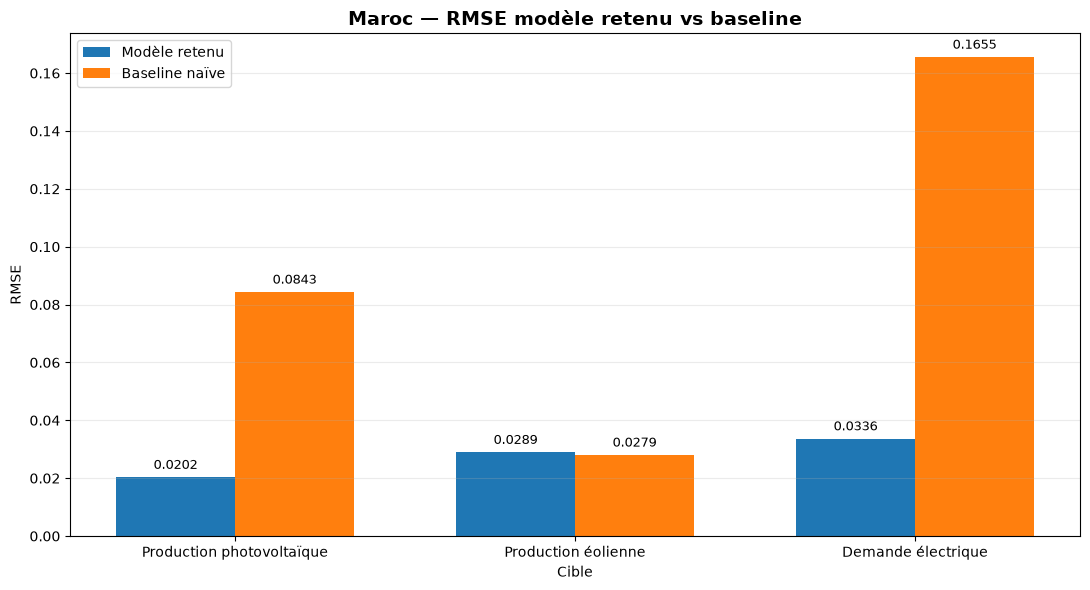

In [15]:
# FIGURE 1 / RMSE MODÈLE VS BASELINE

plot_df = final_test_results_df[
    [
        "Cible",
        "RMSE_test",
        "RMSE_baseline",
    ]
].copy()

x = np.arange(len(plot_df))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))

bars_model = ax.bar(
    x - width / 2,
    plot_df["RMSE_test"],
    width,
    label="Modèle retenu",
)

bars_baseline = ax.bar(
    x + width / 2,
    plot_df["RMSE_baseline"],
    width,
    label="Baseline naïve",
)

ax.set_title(
    "Maroc — RMSE modèle retenu vs baseline",
    fontsize=14,
    fontweight="bold",
)

ax.set_ylabel("RMSE")
ax.set_xlabel("Cible")

ax.set_xticks(x)
ax.set_xticklabels(
    plot_df["Cible"]
)

ax.legend()
ax.grid(
    axis="y",
    alpha=0.25,
)

for bars in [bars_model, bars_baseline]:

    for bar in bars:

        height = bar.get_height()

        ax.annotate(
            f"{height:.4f}",
            xy=(
                bar.get_x()
                + bar.get_width() / 2,
                height,
            ),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9,
        )

plt.tight_layout()

figure_path = (
    FIGURES_DIR
    / "morocco_rmse_vs_baseline.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

print(
    "Figure sauvegardée :",
    figure_path
)

plt.show()

Figure sauvegardée : c:\Users\celes\Desktop\PFE\figures\morocco_pv_real_vs_pred.png


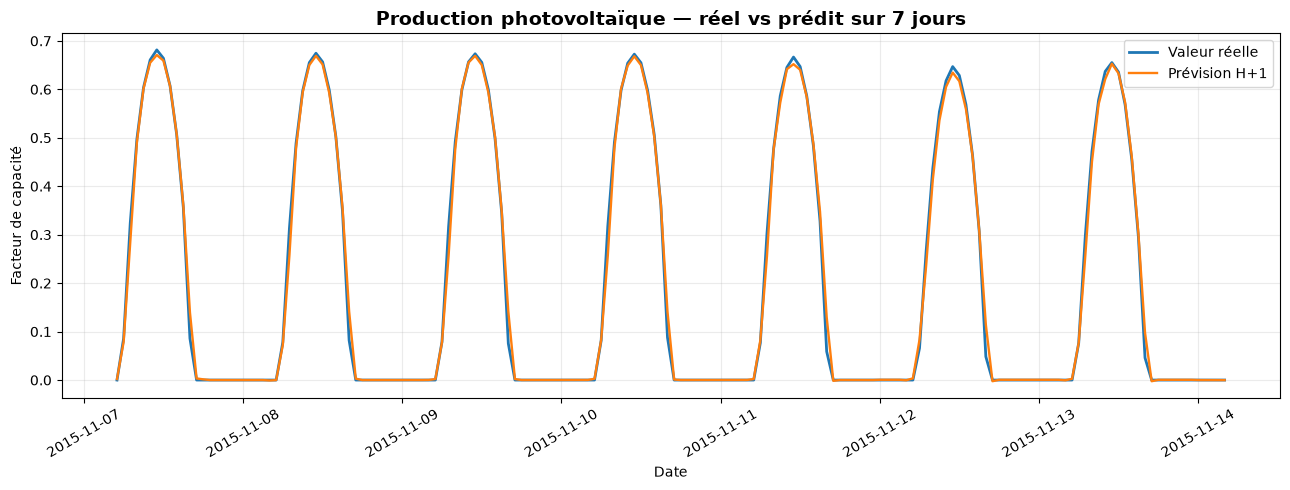

Figure sauvegardée : c:\Users\celes\Desktop\PFE\figures\morocco_wind_real_vs_pred.png


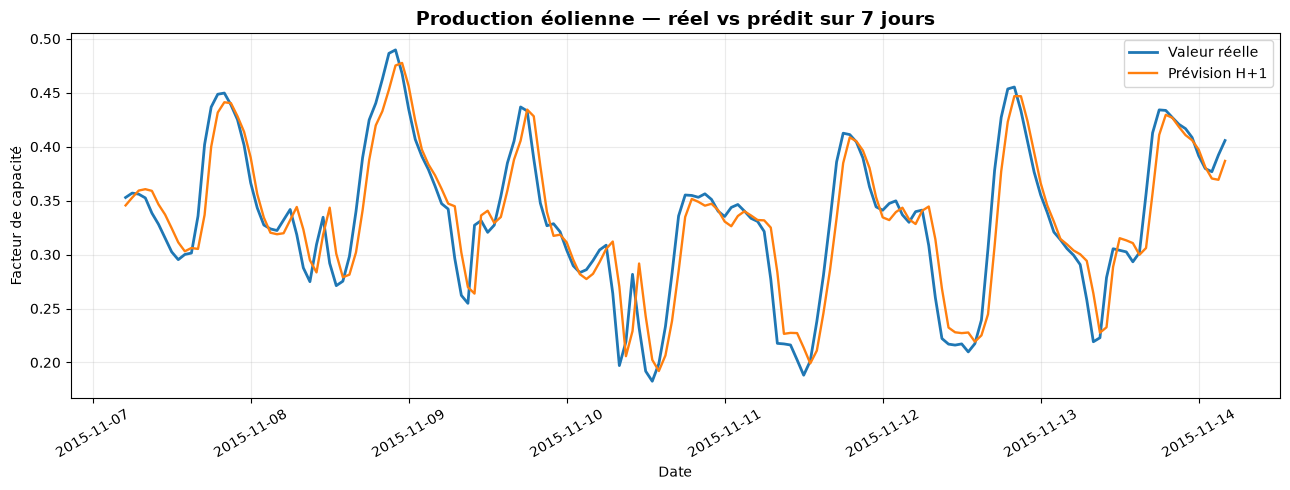

Figure sauvegardée : c:\Users\celes\Desktop\PFE\figures\morocco_demand_real_vs_pred.png


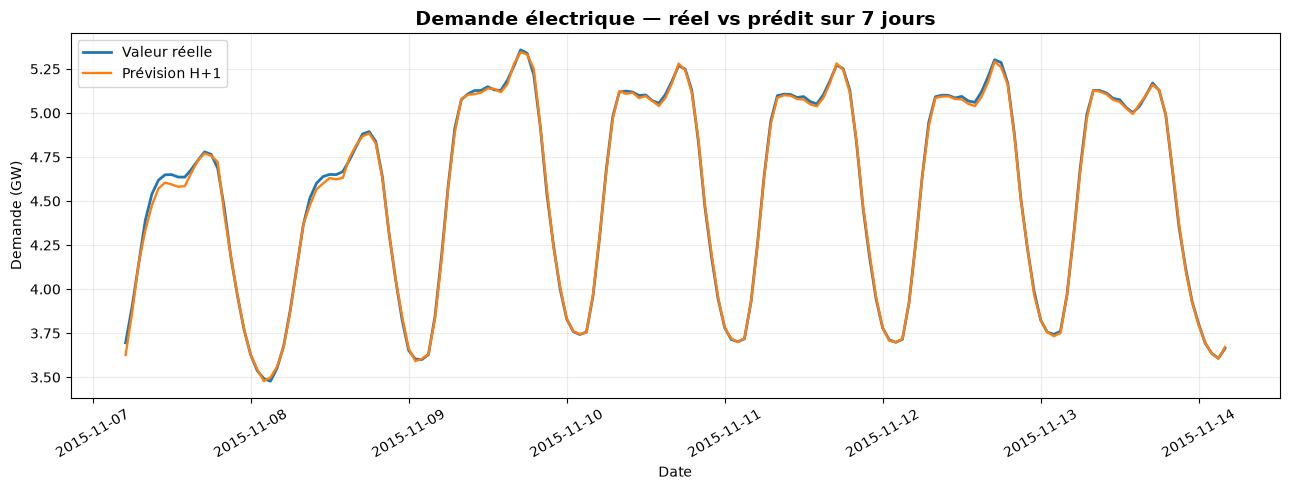

In [16]:
# FIGURES 2 À 4 / RÉEL VS PRÉDIT SUR 7 JOURS

hours_to_display = 24 * 7

file_names = {
    "Production photovoltaïque": "pv",
    "Production éolienne": "wind",
    "Demande électrique": "demand",
}

for target_name in targets:

    predictions = (
        final_predictions[target_name]
        .iloc[:hours_to_display]
        .copy()
    )

    fig, ax = plt.subplots(
        figsize=(13, 5)
    )

    ax.plot(
        predictions["time"],
        predictions["Réel"],
        label="Valeur réelle",
        linewidth=2,
    )

    ax.plot(
        predictions["time"],
        predictions["Prédit"],
        label="Prévision H+1",
        linewidth=1.7,
    )

    ax.set_title(
        f"{target_name} — réel vs prédit sur 7 jours",
        fontsize=14,
        fontweight="bold",
    )

    ax.set_xlabel("Date")

    if target_name == "Demande électrique":
        ax.set_ylabel("Demande (GW)")
    else:
        ax.set_ylabel("Facteur de capacité")

    ax.legend()
    ax.grid(alpha=0.25)

    plt.xticks(
        rotation=30
    )

    plt.tight_layout()

    short_name = file_names[
        target_name
    ]

    figure_path = (
        FIGURES_DIR
        / (
            "morocco_"
            f"{short_name}_real_vs_pred.png"
        )
    )

    fig.savefig(
        figure_path,
        dpi=300,
        bbox_inches="tight"
    )

    print(
        "Figure sauvegardée :",
        figure_path
    )

    plt.show()

# Conclusion du Notebook 09

Cette étude a permis d'évaluer la transférabilité de la méthodologie H+1
dans un contexte énergétique marocain, à partir de profils horaires nationaux
modélisés pour l'année 2015.

Le protocole a respecté une séparation chronologique stricte entre
entraînement, validation et test, ainsi qu'une comparaison systématique
avec une baseline naïve de persistance.

Sur le jeu de test final :

- HistGradientBoosting réduit le RMSE de **75,97 %** pour le photovoltaïque ;
- HistGradientBoosting réduit le RMSE de **79,71 %** pour la demande électrique ;
- pour l'éolien, la régression linéaire obtient un RMSE légèrement supérieur
  à celui de la baseline, avec un gain de **-3,33 %**.

Ces résultats montrent que la méthodologie est particulièrement efficace
pour le photovoltaïque et la demande dans ce contexte, tandis que la prévision
éolienne reste fortement dominée par la persistance à l'horizon H+1.

Cette expérimentation ne constitue pas une validation opérationnelle du réseau
marocain, car les séries solaire et éolienne sont des facteurs de capacité
modélisés et non des mesures réelles de production.

Elle constitue cependant une étude complémentaire de transférabilité dans un
contexte géographique différent, et complète la validation externe allemande
réalisée sur des données énergétiques réelles.